# Escape response curves: LC4 / LPLC2 → giant fiber (DNp01)

Issue #48. The looming detectors `LC4` and `LPLC2` are the main visual inputs to the giant fiber `DNp01`,
the descending neuron that triggers the escape take-off. The README example fires it once; this notebook
measures the response curve on the full MaleCNS brain.

What it measures, for each condition and across many noise seeds (independent flies):

* the probability that each `DNp01` (left and right) fires during a 0.5 s stimulus window,
* the latency to its first spike,
* how both depend on input strength, cell type (`LC4`, `LPLC2`, `LPLC2` subsampled to the `LC4` cell count, both), side (left, right, both) and the
  fraction of the population that is driven,
* whether there is a side bias,
* how `brain.groups["escape_L"]` / `["escape_R"]` relate to `DNp01`, and which other descending neurons respond.

Two controls: no stimulus (the spontaneous rate of `DNp01` from the model's noise), and the same injection into
a size-matched random set of other left visual projection neurons (not LC4/LPLC2).

Run from a fresh install: `pip install flybrain matplotlib`, `flybrain download`, then run all cells.
Plots and a CSV of every number are written to `notebooks/escape_response/`.

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import flybrain
from flybrain import FlyBrain

# outputs go next to this notebook, whether it is run from notebooks/ or from the repo root
HERE = next(p for p in (Path.cwd(), Path.cwd() / "notebooks") if (p / "escape_response.ipynb").exists())
OUT = HERE / "escape_response"
OUT.mkdir(exist_ok=True)

BATCH = 16          # flies run side by side
REPEATS = 2         # batches per condition -> 32 flies (seeds) per condition
F_SUBSETS = 6       # random subsets per point in the fraction sweep, one batch of 16 flies each
WARM = 10           # 0.2 s with no stimulus before each trial
STEPS = 25          # 0.5 s stimulus window (dt = 20 ms)

brain = FlyBrain(batch=BATCH, device="auto")
print("flybrain", getattr(flybrain, "__version__", "?"), "| device", brain.device, "| neurons", brain.n, "| dt", brain.dt)

flybrain 0.1.1 | device cpu | neurons 166700 | dt 0.02


## The cells

In [2]:
gf = {s: brain.cells(["DNp01"], side=s) for s in "LR"}
print("DNp01:", {s: v.tolist() for s, v in gf.items()})
print("escape groups:", {k: brain.groups[k].tolist() for k in ("escape_L", "escape_R")})
for s in "LR":
    print(f"escape_{s} == DNp01 {s}:", np.array_equal(np.sort(brain.groups[f'escape_{s}']), np.sort(gf[s])))

TYPES = {"LC4": ["LC4"], "LPLC2": ["LPLC2"], "LPLC2 matched": ["LPLC2"], "both": ["LC4", "LPLC2"]}
SIDES = {"L": ["L"], "R": ["R"], "both": ["L", "R"]}
# "LPLC2 matched": a fixed random subset of LPLC2 with as many cells as LC4 on each side, so LPLC2 and LC4
# get the same number of injected cells (the full LPLC2 population is larger)
_rng = np.random.default_rng(71)
MATCHED = {s: np.sort(_rng.choice(brain.cells(["LPLC2"], side=s), len(brain.cells(["LC4"], side=s)), replace=False)) for s in "LR"}
def target(types, sides):
    if types == "LPLC2 matched":
        return np.concatenate([MATCHED[s] for s in SIDES[sides]])
    return np.concatenate([brain.cells(TYPES[types], side=s) for s in SIDES[sides]])
for t in TYPES:
    print(t, {s: len(target(t, s)) for s in SIDES})

DNp01: {'L': [6], 'R': [0]}
escape groups: {'escape_L': [6], 'escape_R': [0]}
escape_L == DNp01 L: True
escape_R == DNp01 R: True
LC4 {'L': 71, 'R': 55, 'both': 126}
LPLC2 {'L': 94, 'R': 91, 'both': 185}
LPLC2 matched {'L': 71, 'R': 55, 'both': 126}
both {'L': 165, 'R': 146, 'both': 311}


## Trial runner

One trial = reset with a seed, 0.2 s of rest, then 0.5 s with extra voltage injected every step into the target cells.
`first[side, fly]` is the step of the first `DNp01` spike in the window (−1 = none); latency is
`(step + 1) × dt`, i.e. the end of the step in which it fired. `counts` holds every neuron's spike count in the window.

In [3]:
GF_IDX = np.array([gf["L"][0], gf["R"][0]])

def trial(target_idx, amount, seed):
    brain.reset(seed)
    for _ in range(WARM):
        brain.step()
    first = np.full((2, BATCH), -1)
    counts = np.zeros((brain.n, BATCH), np.int32)
    inject = [(target_idx, amount)] if (target_idx is not None and amount > 0) else []
    for s in range(STEPS):
        fired = brain.step(inject=inject)
        for k, f in enumerate(fired):
            counts[f, k] += 1
            hit = np.isin(GF_IDX, f)
            new = hit & (first[:, k] < 0)
            first[new, k] = s
    return first, counts

def condition(target_idx, amount, seed0=0, subsets=None):
    """REPEATS batches of BATCH flies; seeds seed0 .. seed0+REPEATS-1 (each seeds its own batch of flies).
    subsets: optional list of index arrays, one per batch (for the fraction sweep)."""
    firsts, counts = [], []
    for r in range(REPEATS):
        idx = subsets[r] if subsets is not None else target_idx
        f, c = trial(idx, amount, seed0 + r)
        firsts.append(f); counts.append(c)
    return np.concatenate(firsts, axis=1), np.concatenate(counts, axis=1)

def summarise(first):
    p = (first >= 0).mean(axis=1)
    lat = [((first[j][first[j] >= 0] + 1) * brain.dt * 1000) for j in range(2)]
    return p, lat

def wilson(p, n, z=1.96):
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

# The no-stimulus baseline uses the same seeds (seed0=0) as every stimulus condition below, so it is identical to
# the strength-0 row of each curve. With 32 flies its 95% interval is wide: a different seed range gives a
# different estimate inside that interval.
t0 = time.time()
base_first, base_counts = condition(None, 0.0, seed0=0)
p, lat = summarise(base_first)
n = base_first.shape[1]
for j, s in enumerate("LR"):
    lo, hi = wilson(p[j], n)
    print(f"no stimulus, {n} flies: P(DNp01 {s} fires in 0.5 s) = {p[j]:.3f}  (95% CI {lo:.3f}-{hi:.3f})")
print(f"({time.time()-t0:.1f} s)")

no stimulus, 32 flies: P(DNp01 L fires in 0.5 s) = 0.156  (95% CI 0.069-0.318)
no stimulus, 32 flies: P(DNp01 R fires in 0.5 s) = 0.188  (95% CI 0.089-0.353)
(7.4 s)


## Response curves: strength × cell type × side (all of each population driven)

In [4]:
STRENGTHS = [0.0, 0.005, 0.01, 0.02, 0.03, 0.06, 0.1, 0.15, 0.2, 0.3, 0.5]
rows = []
results = {}
t0 = time.time()
for t in TYPES:
    for side in SIDES:
        if t == "LPLC2 matched" and side == "both":
            continue                       # the matched set is only needed for the one-sided LC4 vs LPLC2 comparison
        idx = target(t, side)
        for a in STRENGTHS:
            # strength 0 injects nothing, so it is the no-stimulus baseline run (same seeds)
            first = base_first if a == 0 else condition(idx, a, seed0=0)[0]
            results[(t, side, a)] = first
            p, lat = summarise(first)
            # left-before-right among flies where both fired, ties counted separately
            both = (first[0] >= 0) & (first[1] >= 0)
            lr = int(((first[0] < first[1]) & both).sum()); rl = int(((first[1] < first[0]) & both).sum())
            tie = int(((first[0] == first[1]) & both).sum())
            rows.append(dict(types=t, side=side, strength=a, n_cells=len(idx), flies=first.shape[1],
                             p_L=p[0], p_R=p[1],
                             lat_L_ms=float(np.mean(lat[0])) if len(lat[0]) else np.nan,
                             lat_L_sd=float(np.std(lat[0])) if len(lat[0]) else np.nan,
                             lat_R_ms=float(np.mean(lat[1])) if len(lat[1]) else np.nan,
                             lat_R_sd=float(np.std(lat[1])) if len(lat[1]) else np.nan,
                             L_first=lr, R_first=rl, same_step=tie))
print(f"{len(rows)} conditions in {time.time()-t0:.0f} s")

import csv
with open(OUT / "curves.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0]))
    w.writeheader(); w.writerows(rows)

def show(rows, keys):
    print("  ".join(f"{k:>10}" for k in keys))
    for r in rows:
        print("  ".join(f"{r[k]:>10.3f}" if isinstance(r[k], float) else f"{str(r[k]):>10}" for k in keys))
show([r for r in rows if r["types"] == "both"], ["side", "strength", "p_L", "p_R", "lat_L_ms", "lat_R_ms", "L_first", "R_first", "same_step"])

121 conditions in 654 s
      side    strength         p_L         p_R    lat_L_ms    lat_R_ms     L_first     R_first   same_step
         L       0.000       0.156       0.188     212.000     223.333           0           1           1
         L       0.005       0.188       0.219     203.333     245.714           0           1           1
         L       0.010       0.375       0.219     190.000     214.286           1           3           1
         L       0.020       0.812       0.219     183.077     208.571           3           1           2
         L       0.030       1.000       0.219     153.750     217.143           6           0           1
         L       0.060       1.000       0.312     110.000     230.000          10           0           0
         L       0.100       1.000       0.312      80.000     226.000          10           0           0
         L       0.150       1.000       0.344      60.625     227.273          11           0           0
         L   

Spread across seeds: a firing probability over N flies gets a 95% Wilson interval; latencies are shown as mean ± SD
over the flies in which that giant fiber fired.

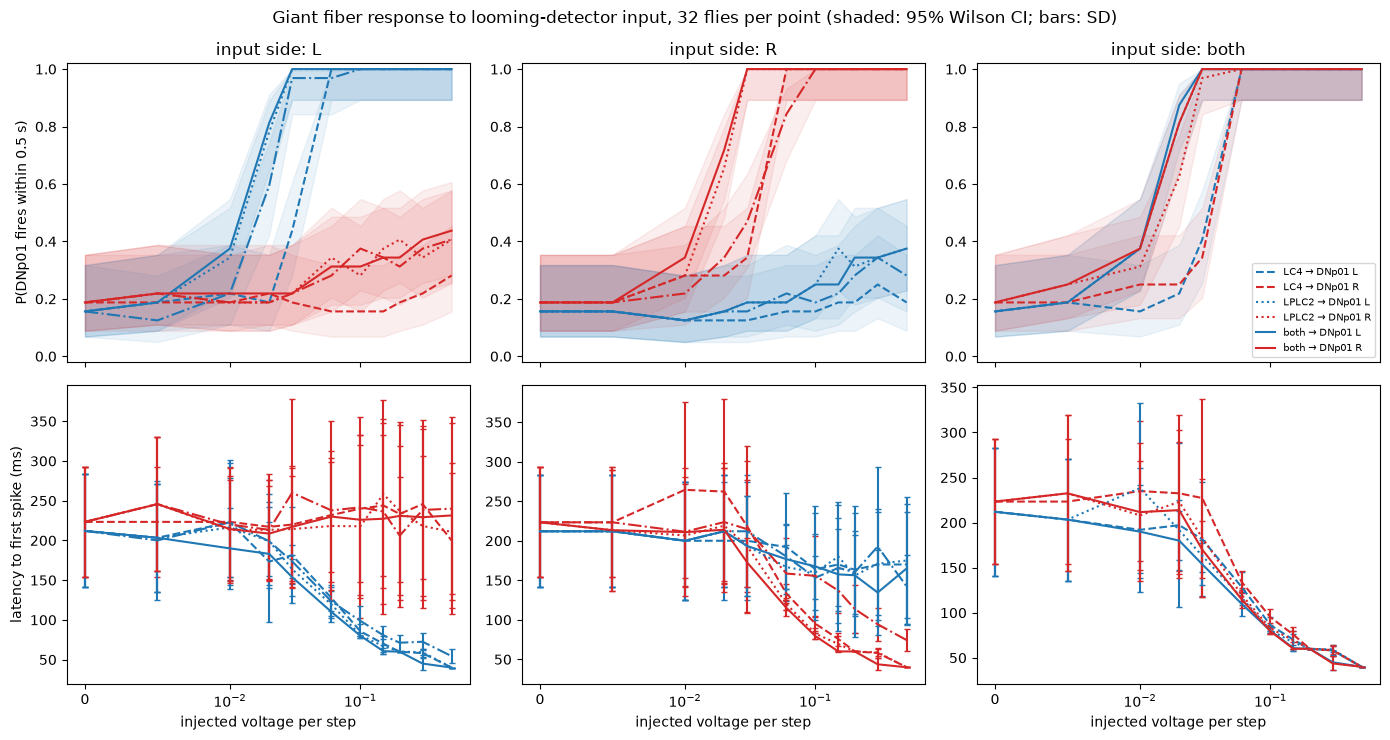

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
colors = {"L": "tab:blue", "R": "tab:red"}
for col, side in enumerate(SIDES):
    for t, ls in zip(TYPES, ["--", ":", "-.", "-"]):
        sub = [r for r in rows if r["types"] == t and r["side"] == side]
        if not sub:
            continue
        x = np.array([r["strength"] for r in sub])
        for gfside in "LR":
            p = np.array([r[f"p_{gfside}"] for r in sub]); n = sub[0]["flies"]
            lo, hi = wilson(p, n)
            axes[0, col].plot(x, p, ls, color=colors[gfside], label=f"{t} → DNp01 {gfside}")
            axes[0, col].fill_between(x, lo, hi, color=colors[gfside], alpha=0.08)
            m = np.array([r[f"lat_{gfside}_ms"] for r in sub]); sd = np.array([r[f"lat_{gfside}_sd"] for r in sub])
            axes[1, col].errorbar(x, m, yerr=sd, fmt=ls, color=colors[gfside], capsize=2)
    axes[0, col].set_title(f"input side: {side}")
    axes[0, col].set_ylim(-0.02, 1.02)
    axes[1, col].set_xlabel("injected voltage per step")
    for r_ in (0, 1): axes[r_, col].set_xscale("symlog", linthresh=0.01)
axes[0, 0].set_ylabel("P(DNp01 fires within 0.5 s)")
axes[1, 0].set_ylabel("latency to first spike (ms)")
axes[0, 2].legend(fontsize=7, loc="lower right")
fig.suptitle(f"Giant fiber response to looming-detector input, {rows[0]['flies']} flies per point (shaded: 95% Wilson CI; bars: SD)")
fig.tight_layout()
fig.savefig(OUT / "response_curves.png", dpi=120)
plt.show()

## Side bias

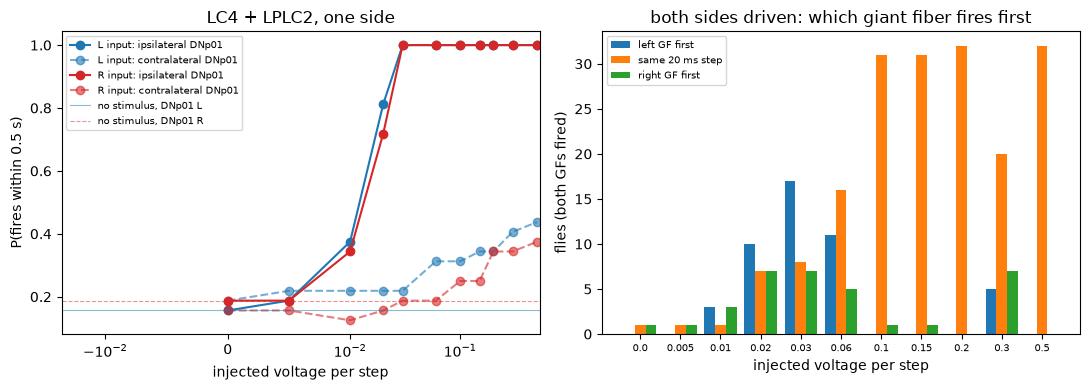

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for side, c in (("L", "tab:blue"), ("R", "tab:red")):
    sub = [r for r in rows if r["types"] == "both" and r["side"] == side]
    x = [r["strength"] for r in sub]
    ipsi = [r[f"p_{side}"] for r in sub]; contra = [r[f"p_{'R' if side == 'L' else 'L'}"] for r in sub]
    ax[0].plot(x, ipsi, "-o", color=c, label=f"{side} input: ipsilateral DNp01")
    ax[0].plot(x, contra, "--o", color=c, alpha=0.6, label=f"{side} input: contralateral DNp01")
base_p = summarise(base_first)[0]          # no-stimulus P for DNp01 L and R, same seeds
for gfside, c, ls in (("L", "tab:blue", "-"), ("R", "tab:red", "--")):
    ax[0].axhline(base_p["LR".index(gfside)], color=c, lw=0.8, ls=ls, alpha=0.5, label=f"no stimulus, DNp01 {gfside}")
ax[0].set_xscale("symlog", linthresh=0.01)
ax[0].set_xlabel("injected voltage per step"); ax[0].set_ylabel("P(fires within 0.5 s)"); ax[0].legend(fontsize=7)
ax[0].set_title("LC4 + LPLC2, one side")

sub = [r for r in rows if r["types"] == "both" and r["side"] == "both"]
x = np.arange(len(sub))
ax[1].bar(x - 0.27, [r["L_first"] for r in sub], 0.27, label="left GF first")
ax[1].bar(x, [r["same_step"] for r in sub], 0.27, label="same 20 ms step")
ax[1].bar(x + 0.27, [r["R_first"] for r in sub], 0.27, label="right GF first")
ax[1].set_xticks(x, [r["strength"] for r in sub]); ax[1].set_xlabel("injected voltage per step")
ax[1].set_ylabel("flies (both GFs fired)"); ax[1].tick_params(axis="x", labelsize=7); ax[1].set_title("both sides driven: which giant fiber fires first"); ax[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "side_bias.png", dpi=120); plt.show()

## Fraction of the population

Both types on the left, a random fraction of the cells driven. Each point below 100% uses `F_SUBSETS` = 6 random
subsets, each run on its own batch of 16 flies (seeds 0-5), drawn with a fixed seed. At 100% every subset is the
full population, so that point is the full-population curve (32 flies, Wilson interval). Which cells are picked matters most at small
fractions, so the unit of replication here is the subset: the plotted value is the mean over subsets and the band is
a 95% interval of that mean across subsets (t distribution, 5 df), not a Wilson interval over all flies.
`p_L_min` / `p_L_max` give the range over subsets.

  fraction     n_cells    strength         p_L   p_L_ci_lo   p_L_ci_hi     p_L_min     p_L_max         p_R    lat_L_ms
     0.050           8       0.060       0.198       0.171       0.225       0.188       0.250       0.188     185.263
     0.050           8       0.100       0.198       0.133       0.262       0.125       0.312       0.156     175.789
     0.050           8       0.200       0.240       0.163       0.316       0.188       0.375       0.198     162.609
     0.050           8       0.500       0.635       0.457       0.813       0.375       0.812       0.219     197.049
     0.100          16       0.060       0.250       0.178       0.322       0.188       0.375       0.198     200.000
     0.100          16       0.100       0.385       0.265       0.506       0.250       0.562       0.198     198.378
     0.100          16       0.200       0.635       0.473       0.798       0.375       0.812       0.240     189.508
     0.100          16       0.500       1.000  

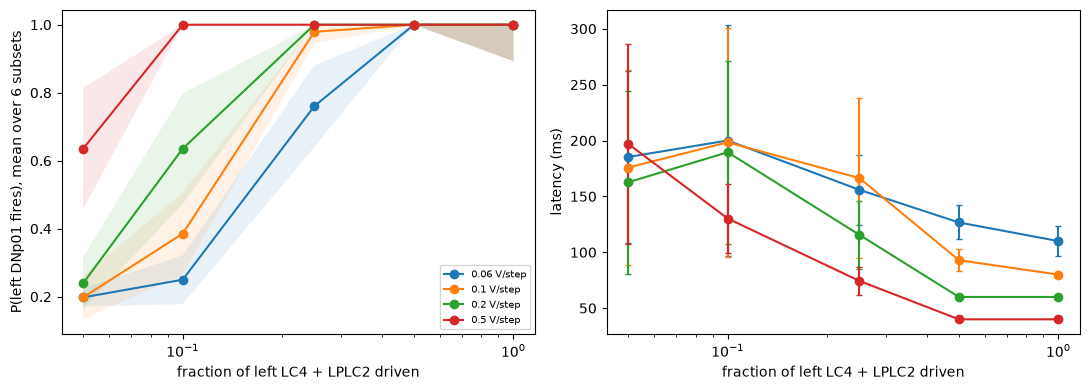

In [7]:
FRACTIONS = [0.05, 0.1, 0.25, 0.5, 1.0]
F_STRENGTHS = [0.06, 0.1, 0.2, 0.5]
left_all = target("both", "L")
rng = np.random.default_rng(48)
from scipy.stats import t as t_dist
T95 = t_dist.ppf(0.975, F_SUBSETS - 1)
frac_rows = []
for frac in FRACTIONS:
    k = max(1, int(round(frac * len(left_all))))
    subsets = [np.sort(rng.choice(left_all, k, replace=False)) for _ in range(F_SUBSETS)] if frac < 1.0 else None
    for a in F_STRENGTHS:
        if frac == 1.0:
            # every cell driven: all subsets are the same set, so this is the full-population curve point
            # (32 flies, Wilson interval)
            f = results[("both", "L", a)]; p_ = float((f[0] >= 0).mean()); lo_, hi_ = wilson(p_, f.shape[1])
            lat_ = (f[0][f[0] >= 0] + 1) * brain.dt * 1000
            frac_rows.append(dict(fraction=frac, n_cells=k, strength=a, subsets=1, flies_per_subset=f.shape[1],
                                  p_L=p_, p_L_ci_lo=float(lo_), p_L_ci_hi=float(hi_), p_L_min=p_, p_L_max=p_,
                                  p_R=float((f[1] >= 0).mean()),
                                  lat_L_ms=float(np.mean(lat_)) if len(lat_) else np.nan,
                                  lat_L_sd=float(np.std(lat_)) if len(lat_) else np.nan))
            continue
        per_sub, lats = [], []
        for r, idx in enumerate(subsets):
            f, _ = trial(idx, a, r)
            per_sub.append((f >= 0).mean(axis=1))
            lats.append((f[0][f[0] >= 0] + 1) * brain.dt * 1000)
        per_sub = np.array(per_sub)                      # (subsets, 2)
        lat_all = np.concatenate(lats)
        se = per_sub[:, 0].std(ddof=1) / np.sqrt(F_SUBSETS)
        frac_rows.append(dict(fraction=frac, n_cells=k, strength=a, subsets=F_SUBSETS, flies_per_subset=BATCH,
                              p_L=float(per_sub[:, 0].mean()), p_L_ci_lo=float(max(0, per_sub[:, 0].mean() - T95 * se)),
                              p_L_ci_hi=float(min(1, per_sub[:, 0].mean() + T95 * se)),
                              p_L_min=float(per_sub[:, 0].min()), p_L_max=float(per_sub[:, 0].max()),
                              p_R=float(per_sub[:, 1].mean()),
                              lat_L_ms=float(np.mean(lat_all)) if len(lat_all) else np.nan,
                              lat_L_sd=float(np.std(lat_all)) if len(lat_all) else np.nan))
with open(OUT / "fractions.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(frac_rows[0])); w.writeheader(); w.writerows(frac_rows)
show(frac_rows, ["fraction", "n_cells", "strength", "p_L", "p_L_ci_lo", "p_L_ci_hi", "p_L_min", "p_L_max", "p_R", "lat_L_ms"])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a in F_STRENGTHS:
    sub = [r for r in frac_rows if r["strength"] == a]
    f = [r["fraction"] for r in sub]
    p = np.array([r["p_L"] for r in sub]); lo = [r["p_L_ci_lo"] for r in sub]; hi = [r["p_L_ci_hi"] for r in sub]
    ax[0].plot(f, p, "-o", label=f"{a} V/step"); ax[0].fill_between(f, lo, hi, alpha=0.1)
    ax[1].errorbar(f, [r["lat_L_ms"] for r in sub], yerr=[r["lat_L_sd"] for r in sub], fmt="-o", capsize=2, label=f"{a} V/step")
for x_ in ax: x_.set_xscale("log"); x_.set_xlabel("fraction of left LC4 + LPLC2 driven")
ax[0].set_ylabel("P(left DNp01 fires), mean over 6 subsets"); ax[1].set_ylabel("latency (ms)"); ax[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "fractions.png", dpi=120); plt.show()

## Specificity control

The same injection into a random, size-matched set of left visual projection neurons that are not LC4 or LPLC2.
If the giant fiber responds just as well, the curve says nothing about the looming pathway.

In [8]:
vpn = brain.cells(["visual_projection"], side="L")
others = np.setdiff1d(vpn, target("both", "both"))
ctrl_idx = np.sort(np.random.default_rng(7).choice(others, len(left_all), replace=False))
print(len(others), "other left visual projection neurons; using", len(ctrl_idx))
ctrl_rows = []
for a in STRENGTHS:
    first = base_first if a == 0 else condition(ctrl_idx, a, seed0=0)[0]
    p, _ = summarise(first)
    real = next(r for r in rows if r["types"] == "both" and r["side"] == "L" and r["strength"] == a)
    ctrl_rows.append(dict(strength=a, control_p_L=p[0], control_p_R=p[1], looming_p_L=real["p_L"], looming_p_R=real["p_R"]))
show(ctrl_rows, ["strength", "looming_p_L", "control_p_L", "looming_p_R", "control_p_R"])

4424 other left visual projection neurons; using 165


  strength  looming_p_L  control_p_L  looming_p_R  control_p_R
     0.000       0.156       0.156       0.188       0.188
     0.005       0.188       0.125       0.219       0.188
     0.010       0.375       0.125       0.219       0.188
     0.020       0.812       0.125       0.219       0.188
     0.030       1.000       0.125       0.219       0.219
     0.060       1.000       0.094       0.312       0.188
     0.100       1.000       0.094       0.312       0.188
     0.150       1.000       0.094       0.344       0.156
     0.200       1.000       0.094       0.344       0.125
     0.300       1.000       0.094       0.406       0.125
     0.500       1.000       0.094       0.438       0.125


## Other descending neurons

Spikes per second over the 0.5 s window for every descending neuron, left LC4 + LPLC2 at two strengths versus no
stimulus (same 32 flies' seeds). Ranked by the increase, grouped by cell type and side. `z` is the increase divided
by its standard error across flies.

In [9]:
dn = brain.cells(["descending_neuron"])
win = STEPS * brain.dt
def dn_rates(counts):
    return counts[dn] / win            # (n_dn, flies)

base_c = base_counts                     # the no-stimulus run, same seeds
labels = np.array([f"{brain.cell_type[i]}_{brain.side[i]}" for i in dn])
for a in (0.1, 0.3):
    _, c = condition(left_all, a, seed0=0)
    diff = dn_rates(c) - dn_rates(base_c)            # paired by seed
    out = []
    for lab in np.unique(labels):
        m = labels == lab
        d = diff[m].mean(axis=0)                     # per fly, mean over the cells of this type/side
        se = d.std(ddof=1) / np.sqrt(len(d))
        out.append((lab, int(m.sum()), d.mean(), d.mean() / se if se > 0 else np.inf))
    out.sort(key=lambda r: -r[2])
    print(f"\nleft LC4 + LPLC2 at {a} V/step: top descending-neuron types by increase (spikes/s)")
    print(f"{'type_side':>16} {'cells':>5} {'Δ rate':>8} {'z':>7}")
    for lab, n_, d, z in out[:12]:
        print(f"{lab:>16} {n_:>5} {d:8.2f} {z:7.1f}")


left LC4 + LPLC2 at 0.1 V/step: top descending-neuron types by increase (spikes/s)
       type_side cells   Δ rate       z
         DNp04_L     1    16.25    65.0
         DNp01_L     1     9.38    56.3
         DNp02_L     1     7.75    52.0
         DNg40_L     1     7.69    58.9
         DNp11_L     1     6.12    49.0
         DNp03_L     1     6.00    27.3
         DNp71_L     1     5.94    35.4
       DNpe056_L     1     5.94    54.3
        DNp103_L     1     5.25    26.8
         DNp05_L     1     4.44    25.6
       DNae004_R     1     4.12    23.1
         DNp06_L     1     3.81    23.2



left LC4 + LPLC2 at 0.3 V/step: top descending-neuron types by increase (spikes/s)
       type_side cells   Δ rate       z
         DNp04_L     1    29.06    72.4
         DNp01_L     1    18.06    85.9
         DNp02_L     1    16.69    63.3
         DNg40_L     1    13.81    66.4
         DNp11_L     1    11.00    61.2
       DNpe056_L     1    10.88    61.0
         DNp71_L     1    10.81    54.6
         DNp03_L     1    10.12    50.7
        DNp103_L     1     9.19    52.1
         DNp05_L     1     7.69    32.1
         DNp06_L     1     7.25    37.0
       DNae004_R     1     7.06    35.2


## What the model leaves out

* **No real visual input.** Looming detectors are driven by injecting voltage, not by an expanding image on the eye,
  so size, speed and approach angle (the variables Ache et al. 2019 relate to giant fiber timing) are not modelled.
  The strength axis is a model voltage, not a physical stimulus.
* **No VNC dynamics beyond the connectome.** `DNp01` spiking is the readout; the jump motor circuit, muscles and
  the take-off itself are not simulated, and gap junctions (the giant fiber's fast electrical synapses) are not in
  the chemical-synapse weight matrix.
* **Fixed weight gain and hand-calibrated neuron parameters.** One leaky integrate-and-fire model with the same
  `gain`, `tonic`, `tau` and noise for every neuron; nothing was tuned here. Spontaneous `DNp01` spikes come from
  the model noise, which sets the no-stimulus baseline.
* **20 ms time steps.** Latencies are quantised to 20 ms and the shortest possible latency is one step, far coarser
  than the few-ms real giant fiber pathway, so latencies here compare conditions, not the animal.
* **One brain.** All flies share MaleCNS v1.0 wiring; seeds only change the noise.